Loading Data

In [15]:
from Bio import SeqIO
import pandas as pd

sequences = []
coords = []

#Fasta file for ACRs
for record in SeqIO.parse("/Users/avery/Downloads/dACR.fa", "fasta"):
    sequences.append(str(record.seq))
    coords.append(record.id)

gff = pd.read_csv(
    "/Users/avery/fimo_collapsed_with_metadata.csv"
)

def extract_alias(attr):
    for field in attr.split(";"):
        if field.startswith("Alias="):
            return field.split("=")[1]
    return None

gff["Alias"] = gff["attributes"].apply(extract_alias)
gff["sequence_id"] = gff["seqid"].astype(str).str.strip()

Count Matrix (zero-hits excluded)

In [16]:
from sklearn.preprocessing import normalize

#ACR by Motif Family count matrix
count_df = pd.crosstab(
    gff["sequence_id"],
    gff["Alias"]
)

#Sorted by total non-redundant motif intervals per ACR
count_df["Total_Motif_Intervals"] = count_df.sum(axis=1)
count_df = count_df.sort_values(by="Total_Motif_Intervals", ascending=False)

#Normalizing count matrix
count_df = pd.DataFrame(
    normalize(
        count_df.drop(columns=["Total_Motif_Intervals"]),
        norm="l1",
        axis=1
    ),
    index=count_df.index,
    columns=count_df.drop(columns=["Total_Motif_Intervals"]).columns
)
print(count_df.shape)

(19033, 28)


In [17]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

X_count = count_df

# Optimal k for count matrix
kmeans_count = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=20
)
count_df["kmeans_cluster"] = kmeans_count.fit_predict(X_count)
print(count_df["kmeans_cluster"].value_counts())

kmeans_cluster
2    5858
0    4268
1    3459
3    2902
4    2546
Name: count, dtype: int64


In [18]:
#Creating TF-IDF matrix where words are CREs and documents are ACRs
from sklearn.feature_extraction.text import TfidfVectorizer

# Remove records without a CRE alias
gff = gff.dropna(subset=["Alias"])

# Create one document per ACR, with CRE aliases as its words
acr_to_cres = (
    gff.groupby("sequence_id")["Alias"]
    .apply(list)
)

documents = acr_to_cres.apply(lambda cres: " ".join(cres))

# Construct the TF-IDF matrix
vectorizer = TfidfVectorizer(
    lowercase=False,
    token_pattern=r"(?u)\b\S+\b"
)

tfidf_matrix = vectorizer.fit_transform(documents)

# Convert to a DataFrame
tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=vectorizer.get_feature_names_out(),
    index=documents.index
)

# Display results
pd.set_option("display.max_columns", None)

print("TF-IDF matrix shape:", tfidf_df.shape)
print(tfidf_df.head())

TF-IDF matrix shape: (19033, 28)
                         AGL6  AS2  AT4G12670      BPC1      BPC5      BPC6  \
sequence_id                                                                   
Chr1_1000253to1001194     0.0  0.0        0.0  0.555130  0.553597  0.514208   
Chr1_10023455to10024241   0.0  0.0        0.0  0.555130  0.553597  0.514208   
Chr1_10025693to10026874   0.0  0.0        0.0  0.000000  0.000000  0.000000   
Chr1_10027187to10027945   0.0  0.0        0.0  0.000000  0.000000  0.000000   
Chr1_10028983to10029244   0.0  0.0        0.0  0.431873  0.000000  0.000000   

                         CDF5  DOF1.5  DOF3.4    DOF3.6    DOF5.1  DOF5.8  \
sequence_id                                                                 
Chr1_1000253to1001194     0.0     0.0     0.0  0.347779  0.000000     0.0   
Chr1_10023455to10024241   0.0     0.0     0.0  0.347779  0.000000     0.0   
Chr1_10025693to10026874   0.0     0.0     0.0  0.718147  0.695892     0.0   
Chr1_10027187to10027945   0.

In [19]:
X = tfidf_df.copy()

kmeans_labels = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=20
).fit_predict(X)

results = X.copy()
results["kmeans_cluster"] = kmeans_labels

In [20]:
import numpy as np
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    adjusted_rand_score
)

##########################################################
# PREPARE BOTH FEATURE MATRICES
##########################################################

# Remove any previously added cluster-label columns
X_count = count_df.drop(
    columns=["kmeans_cluster", "hierarchical_cluster"],
    errors="ignore"
).copy()

X_tfidf = tfidf_df.copy()

# Keep only ACRs present in BOTH representations
common_acrs = X_count.index.intersection(X_tfidf.index)

X_count = X_count.loc[common_acrs].sort_index()
X_tfidf = X_tfidf.loc[common_acrs].sort_index()

print("Count matrix shape:", X_count.shape)
print("TF-IDF matrix shape:", X_tfidf.shape)
print("Same ACR order:", X_count.index.equals(X_tfidf.index))

##########################################################
# KMEANS CLUSTERING
##########################################################

k = 5

# Count representation
kmeans_count = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=20
)

count_labels = kmeans_count.fit_predict(X_count)

# TF-IDF representation
kmeans_tfidf = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

tfidf_labels = kmeans_tfidf.fit_predict(X_tfidf)

# Store cluster labels separately from feature matrices
count_results = pd.DataFrame({
    "sequence_id": X_count.index,
    "kmeans_cluster": count_labels
}).set_index("sequence_id")

tfidf_results = pd.DataFrame({
    "sequence_id": X_tfidf.index,
    "kmeans_cluster": tfidf_labels
}).set_index("sequence_id")

print("\nCount cluster sizes:")
print(count_results["kmeans_cluster"].value_counts().sort_index())

print("\nTF-IDF cluster sizes:")
print(tfidf_results["kmeans_cluster"].value_counts().sort_index())

##########################################################
# KMEANS STABILITY
##########################################################

def kmeans_stability(X, n_clusters=5, runs=10):

    label_sets = []

    for seed in range(runs):
        labels = KMeans(
            n_clusters=n_clusters,
            random_state=seed,
            n_init=10
        ).fit_predict(X)

        label_sets.append(labels)

    ari_scores = []

    for i in range(runs):
        for j in range(i + 1, runs):
            ari_scores.append(
                adjusted_rand_score(
                    label_sets[i],
                    label_sets[j]
                )
            )

    return np.mean(ari_scores)

##########################################################
# EVALUATION
##########################################################

def evaluate(X, labels, representation):

    labels = np.asarray(labels)

    cluster_sizes = pd.Series(labels).value_counts()

    silhouette = silhouette_score(X, labels)
    calinski = calinski_harabasz_score(X, labels)
    davies = davies_bouldin_score(X, labels)

    stability = kmeans_stability(
        X,
        n_clusters=5,
        runs=10
    )

    return {
        "Representation": representation,
        "Method": "KMeans",
        "Clusters": len(cluster_sizes),
        "Largest Cluster": cluster_sizes.max(),
        "Smallest Cluster": cluster_sizes.min(),
        "Silhouette": silhouette,
        "Calinski-Harabasz": calinski,
        "Davies-Bouldin": davies,
        "ARI Stability": stability
    }

##########################################################
# COMPARE COUNT AND TF-IDF
##########################################################

evaluation_results = []

evaluation_results.append(
    evaluate(X_count, count_labels, "Count")
)

evaluation_results.append(
    evaluate(X_tfidf, tfidf_labels, "TF-IDF")
)

results_df = pd.DataFrame(evaluation_results)

results_df.to_csv(
    "kmeans_count_vs_tfidf_evaluation.csv",
    index=False
)

print("\nK-means evaluation comparison:")
print(results_df.to_string(index=False))

Count matrix shape: (19033, 28)
TF-IDF matrix shape: (19033, 28)
Same ACR order: True

Count cluster sizes:
kmeans_cluster
0    2700
1    4616
2    5076
3    4684
4    1957
Name: count, dtype: int64

TF-IDF cluster sizes:
kmeans_cluster
0    4494
1    4543
2    4682
3    1838
4    3476
Name: count, dtype: int64

K-means evaluation comparison:
Representation Method  Clusters  Largest Cluster  Smallest Cluster  Silhouette  Calinski-Harabasz  Davies-Bouldin  ARI Stability
         Count KMeans         5             5076              1957    0.364656        6591.562547         1.51486       0.706637
        TF-IDF KMeans         5             4682              1838    0.375835        5182.915283         1.46545       0.796189


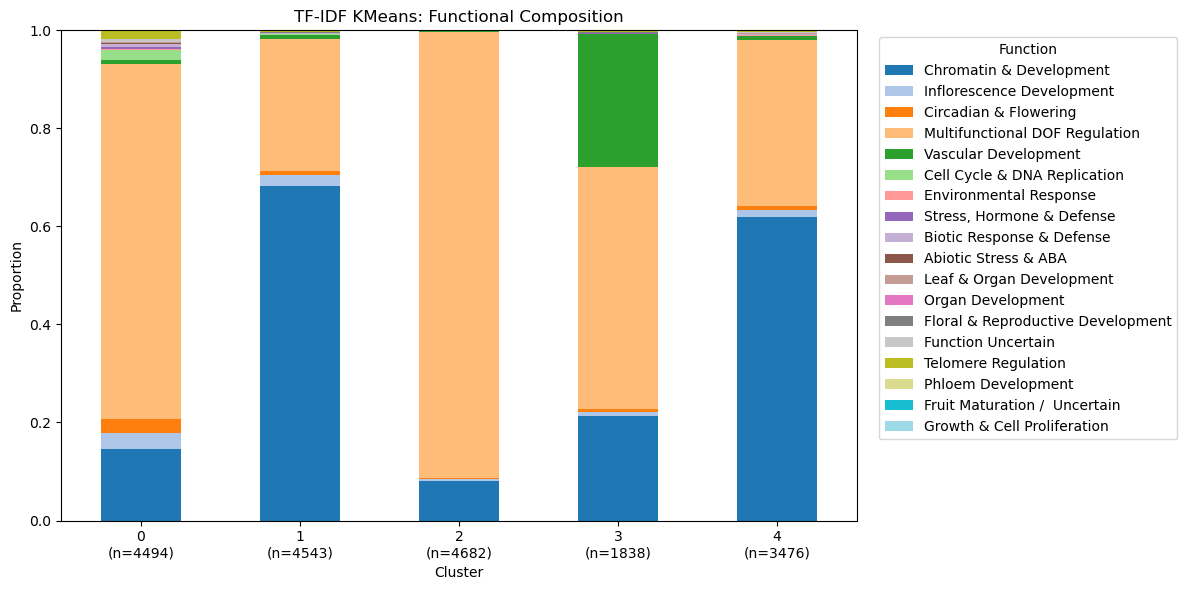

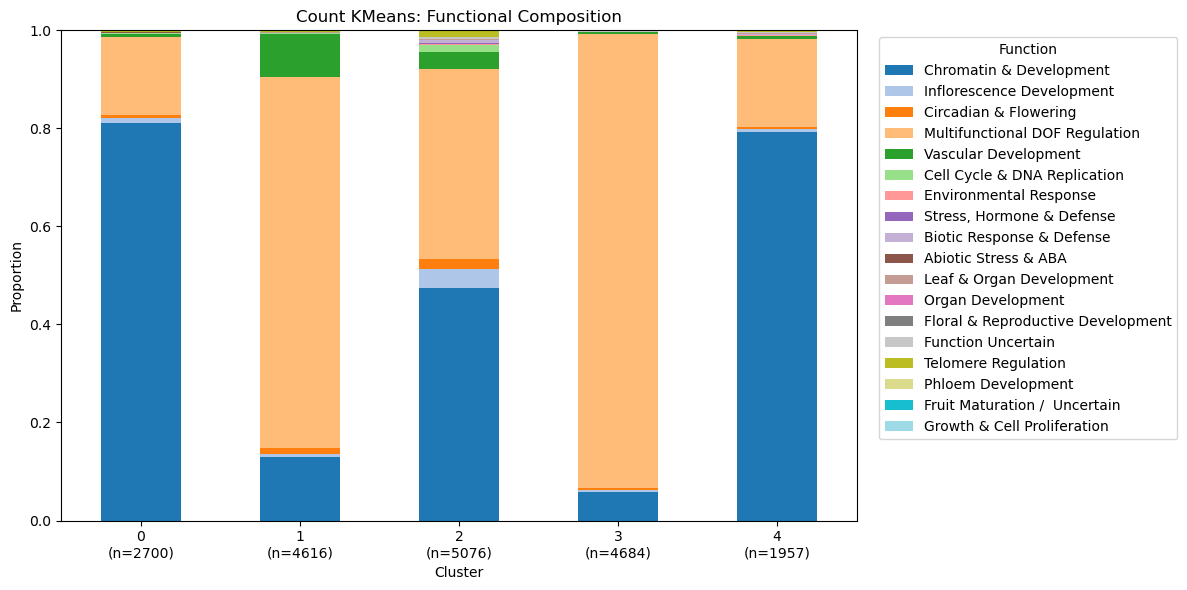

In [21]:
import matplotlib.pyplot as plt

##########################################################
# FUNCTION DEFINITIONS
##########################################################

functional_groups = {
    'Chromatin & Development': ['BPC1', 'BPC5', 'BPC6'],
    'Inflorescence Development': ['RAMOSA1'],
    'Circadian & Flowering': ['CDF5'],
    'Multifunctional DOF Regulation': ['DOF3.6', 'DOF5.1', 'DOF3.4', 'DOF1.5'],
    'Vascular Development': ['DOF5.8'],
    'Cell Cycle & DNA Replication': ['E2FD', 'E2FE'],
    'Environmental Response': ['DREB2D', 'ERF095'],
    'Stress, Hormone & Defense': ['ERF014', 'ERF057', 'ERF091', 'ERF104', 'ERF2', 'ERF5'],
    'Biotic Response & Defense': ['ERF9'],
    'Abiotic Stress & ABA': ['RAP2-6'],
    'Leaf & Organ Development': ['AS2'],
    'Organ Development': ['LOB'],
    'Floral & Reproductive Development': ['AGL6'],
    'Function Uncertain': ['AT4G12670'],
    'Telomere Regulation': ['TRP1', 'TRP2'],
    'Phloem Development': ['NAC020'],
    'Fruit Maturation /  Uncertain': ['NAC058'],
    'Growth & Cell Proliferation': ['TCP14']
}


alias_to_function = {
    motif: func
    for func, motifs in functional_groups.items()
    for motif in motifs
}

##########################################################
# FUNCTION ANNOTATION (ONLY IF NOT ALREADY PRESENT)
##########################################################

if "Function" not in gff.columns:
    gff["Alias"] = gff["attributes"].str.extract(r"Alias=([^;]+)")
    gff["Function"] = gff["Alias"].map(alias_to_function)

if "sequence_id" not in gff.columns:
    gff["sequence_id"] = gff["seqid"].astype(str).str.strip()

##########################################################
# FUNCTION MAPPING
##########################################################

all_functions = list(functional_groups.keys())

##########################################################
# FUNCTIONAL COMPOSITION
##########################################################

def get_cluster_composition(cluster_labels, acr_ids):

    # Map the actual ACR IDs used in clustering to their cluster labels
    cluster_map = dict(zip(acr_ids, cluster_labels))

    temp = gff.copy()

    temp["cluster"] = temp["sequence_id"].map(cluster_map)

    # Keep only annotated motif hits assigned to a cluster
    temp = temp.dropna(subset=["Function", "cluster"])

    # Count motif-hit records by cluster and functional group
    counts = pd.crosstab(
        temp["cluster"],
        temp["Function"]
    ).reindex(
        index=sorted(set(cluster_labels)),
        columns=all_functions,
        fill_value=0
    )

    # Convert counts into proportions within each cluster
    proportions = counts.div(
        counts.sum(axis=1).replace(0, np.nan),
        axis=0
    ).fillna(0)

    # Count the number of ACRs in each cluster
    cluster_sizes = (
        pd.Series(cluster_labels, index=acr_ids)
        .groupby(level=0)
        .first()
    )

    cluster_sizes = (
        pd.Series(cluster_labels)
        .value_counts()
        .sort_index()
    )

    return proportions, cluster_sizes

##########################################################
# PLOTTING
##########################################################

def plot_stacked(df, cluster_sizes, title):

    ax = df.plot(
        kind="bar",
        stacked=True,
        figsize=(12,6),
        colormap="tab20"
    )

    labels = [
        f"{cluster}\n(n={cluster_sizes.loc[cluster]})"
        for cluster in df.index
    ]

    ax.set_xticklabels(labels, rotation=0)

    plt.ylabel("Proportion")
    plt.xlabel("Cluster")
    plt.title(title)
    plt.ylim(0,1)

    plt.legend(
        title="Function",
        bbox_to_anchor=(1.02,1),
        loc="upper left"
    )

    plt.tight_layout()
    plt.show()

##########################################################
# PLOTS
##########################################################
plots = [
    ("TF-IDF KMeans", tfidf_labels, X_tfidf.index),
    ("Count KMeans", count_labels, X_count.index)
]

for title, labels, acr_ids in plots:

    composition, cluster_sizes = get_cluster_composition(
        labels,
        acr_ids
    )

    plot_stacked(
        composition,
        cluster_sizes,
        f"{title}: Functional Composition"
    )

In [22]:
import pandas as pd
import numpy as np

from scipy.stats import chi2_contingency, entropy

##########################################################
# BIOLOGICAL EVALUATION
##########################################################

def biological_summary(cluster_labels, acr_ids, method):

    temp = gff.copy()

    # Map each ACR to its correct K-means cluster
    cluster_map = dict(zip(acr_ids, cluster_labels))

    temp["cluster"] = temp["sequence_id"].map(cluster_map)

    # Keep annotated motif hits belonging to clustered ACRs
    temp = temp.dropna(subset=["Function", "cluster"])

    # Cluster sizes: number of unique ACRs, not GFF rows
    cluster_sizes = (
        pd.Series(cluster_labels, index=acr_ids)
        .groupby(level=0)
        .first()
        .value_counts()
        .sort_index()
    )

    ######################################################
    # CONTINGENCY TABLE
    ######################################################

    counts = pd.crosstab(
        temp["cluster"],
        temp["Function"]
    ).reindex(
        index=cluster_sizes.index,
        columns=all_functions,
        fill_value=0
    )

    ######################################################
    # CHI-SQUARE TEST
    ######################################################

    # Remove functional groups with zero counts across all clusters
    chi_counts = counts.loc[:, counts.sum(axis=0) > 0]

    # Chi-square requires at least 2 clusters and 2 functions
    if chi_counts.shape[0] >= 2 and chi_counts.shape[1] >= 2:
        chi2, p, dof, expected = chi2_contingency(chi_counts)

        p_value = (
            "<0.001" if p < 0.001 else f"{p:.3f}"
        )
    else:
        p_value = "N/A"

    ######################################################
    # FUNCTIONAL PROPORTIONS
    ######################################################

    proportions = counts.div(
        counts.sum(axis=1).replace(0, np.nan),
        axis=0
    ).fillna(0)

    ######################################################
    # SUMMARY TABLE
    ######################################################

    rows = []

    for cluster in proportions.index:

        # Top three functional groups
        top3 = (
            proportions.loc[cluster]
            .sort_values(ascending=False)
            .head(3)
        )

        # Shannon diversity, base 2
        shannon = entropy(
            proportions.loc[cluster].values,
            base=2
        )

        # Handle cases where fewer than three functions are present
        top_functions = list(top3.items())

        while len(top_functions) < 3:
            top_functions.append(("N/A", 0.0))

        rows.append({
            "Representation": method,
            "Chi-square p": p_value,
            "Cluster": cluster,
            "Cluster Size (ACRs)": int(cluster_sizes.loc[cluster]),
            "Annotated Motif Hits": int(counts.loc[cluster].sum()),
            "Shannon Diversity Index": round(shannon, 3),

            "Top Function 1": top_functions[0][0],
            "Top 1 (%)": round(top_functions[0][1] * 100, 2),

            "Top Function 2": top_functions[1][0],
            "Top 2 (%)": round(top_functions[1][1] * 100, 2),

            "Top Function 3": top_functions[2][0],
            "Top 3 (%)": round(top_functions[2][1] * 100, 2)
        })

    return pd.DataFrame(rows)


##########################################################
# RUN: COUNT AND TF-IDF K-MEANS
##########################################################

bio_results = pd.concat([

    biological_summary(
        cluster_labels=count_labels,
        acr_ids=X_count.index,
        method="Count KMeans"
    ),

    biological_summary(
        cluster_labels=tfidf_labels,
        acr_ids=X_tfidf.index,
        method="TF-IDF KMeans"
    )

], ignore_index=True)


##########################################################
# SAVE AND DISPLAY
##########################################################

bio_results.to_csv(
    "count_vs_tfidf_biological_summary.csv",
    index=False
)

print(bio_results.to_string(index=False))

Representation Chi-square p  Cluster  Cluster Size (ACRs)  Annotated Motif Hits  Shannon Diversity Index                 Top Function 1  Top 1 (%)                 Top Function 2  Top 2 (%)            Top Function 3  Top 3 (%)
  Count KMeans       <0.001        0                 2700                  7089                    0.890        Chromatin & Development      81.14 Multifunctional DOF Regulation      16.01 Inflorescence Development       0.92
  Count KMeans       <0.001        1                 4616                 16169                    1.187 Multifunctional DOF Regulation      75.62        Chromatin & Development      12.98      Vascular Development       8.88
  Count KMeans       <0.001        2                 5076                 22769                    1.818        Chromatin & Development      47.50 Multifunctional DOF Regulation      38.79 Inflorescence Development       3.89
  Count KMeans       <0.001        3                 4684                  7696                 